# 02b — Protocolo de pré-processamento

Complementa o `02_preprocessing.ipynb` (comparação exploratória de configurações com
split 80/20 e PCA). Este notebook define a preparação usada pelo modelo publicado
(notebooks 03 a 05): correção do horário 24:00, split cronológico treino / validação /
teste e transformações ajustadas só no treino.

Transforma a base bruta em entradas reproduzíveis para a modelagem, sem vazamento de
informação entre períodos e sem usar `Load_Type` como feature.

A lógica reutilizável está em `src/regime_anomaly/preprocessing.py`; este notebook
registra **as evidências** que sustentam cada decisão.

!!! warning "Decisões propostas"
    As escolhas abaixo são propostas fundamentadas, pendentes de aprovação da equipe.
    A seção final lista o que está decidido e o que continua em aberto.

**Regras de vazamento adotadas**

1. Etapas linha a linha (correção de timestamp, features de calendário) podem rodar na
   base inteira, pois não aprendem nada dos dados.
2. Qualquer estatística (média, desvio, escala) é ajustada **somente no treino**.
3. O período de **teste fica congelado**: aqui só contamos linhas, sem olhar valores.
4. `Load_Type` é consultado apenas para diagnosticar sua natureza, e só no treino.

In [1]:
import hashlib
import json
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn


def find_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Raiz do projeto não encontrada.")


ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))

from regime_anomaly import preprocessing as pp
from regime_anomaly.config import (
    IMAGES_DIR,
    METADATA_DIR,
    PROCESSED_DIR,
    RANDOM_STATE,
    TABLES_DIR,
    ensure_artifact_dirs,
)
from regime_anomaly.data import DEFAULT_DATASET, load_data

ensure_artifact_dirs()

# Mesma paleta Okabe-Ito do EDA.
HIGH_CONTRAST_PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]
SPLIT_COLORS = dict(zip(pp.SPLIT_NAMES, HIGH_CONTRAST_PALETTE[:3]))
sns.set_theme(style="whitegrid", palette=HIGH_CONTRAST_PALETTE)
pd.set_option("display.max_columns", 30)


def save_figure(fig, name: str) -> None:
    fig.savefig(IMAGES_DIR / name, dpi=150, bbox_inches="tight")


def save_table(frame: pd.DataFrame, name: str, index: bool = True) -> None:
    frame.to_csv(TABLES_DIR / name, index=index, encoding="utf-8-sig")

# load_data() mantém os nomes originais da UCI; o protocolo trabalha em snake_case.
LABEL_COLUMN = pp.LABEL


## 1. Leitura e rastreabilidade

O hash SHA-256 do arquivo bruto fica registrado nos metadados, para que qualquer
resultado posterior possa ser ligado exatamente a esta versão da base.

In [2]:
raw_sha256 = hashlib.sha256(DEFAULT_DATASET.read_bytes()).hexdigest()
raw = pp.normalize_columns(load_data())
print(f"Arquivo: {DEFAULT_DATASET.relative_to(ROOT)}")
print(f"SHA-256: {raw_sha256}")
print(f"Formato: {raw.shape[0]:,} linhas × {raw.shape[1]} colunas")
raw.head()

Arquivo: artifacts\data\raw\Steel_industry_data.csv
SHA-256: 9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0fae3c643e82072eacc
Formato: 35,040 linhas × 11 colunas


,date,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,co2_tco2,lagging_current_power_factor,leading_current_power_factor,nsm,weekstatus,day_of_week,load_type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


## 2. Correção do registro de meia-noite

O arquivo marca cada leitura pelo **fim** do intervalo de 15 minutos (a primeira linha é
`01/01/2018 00:15`). A leitura que fecha o dia (24:00) aparece **depois** da leitura de
23:45, mas com a data do próprio dia e `NSM = 0`. Um parse ingênuo a coloca 24 horas
antes do lugar correto, e a série deixa de ser monotônica.

In [3]:
naive = pd.to_datetime(raw[pp.DATE_COLUMN], dayfirst=True)
print("Ordem original do arquivo, ao redor da primeira virada de dia:")
display(raw.loc[93:97, [pp.DATE_COLUMN, pp.NSM, pp.DAY_OF_WEEK, pp.USAGE]])

naive_steps = naive.diff().value_counts().rename("ocorrencias").to_frame()
naive_steps.index = naive_steps.index.astype(str)
print("Intervalos entre linhas consecutivas com parse ingênuo:")
display(naive_steps)

Ordem original do arquivo, ao redor da primeira virada de dia:


,date,nsm,day_of_week,usage_kwh
93,01/01/2018 23:30,84600,Monday,3.24
94,01/01/2018 23:45,85500,Monday,3.67
95,01/01/2018 00:00,0,Monday,3.42
96,02/01/2018 00:15,900,Tuesday,3.20
97,02/01/2018 00:30,1800,Tuesday,3.85


Intervalos entre linhas consecutivas com parse ingênuo:


,ocorrencias
date,
0 days 00:15:00,34310
-1 days +00:15:00,365
1 days 00:15:00,364


A correção soma um dia às leituras de 00:00 e reordena a série. `day_of_week` e
`WeekStatus` mantêm a convenção da fonte (o dia ao qual o intervalo pertence), o que
confere com a posição dessas linhas no arquivo.

In [4]:
timestamped = pp.parse_timestamps(raw)
fixed_steps = timestamped[pp.TIMESTAMP_COLUMN].diff().value_counts().rename("ocorrencias")
fixed_steps.index = fixed_steps.index.astype(str)
display(fixed_steps.to_frame())
print(
    "Início:",
    timestamped[pp.TIMESTAMP_COLUMN].min(),
    "| Fim:",
    timestamped[pp.TIMESTAMP_COLUMN].max(),
)

,ocorrencias
timestamp,
0 days 00:15:00,35039


Início: 2018-01-01 00:15:00 | Fim: 2019-01-01 00:00:00


## 3. Validação estrutural

`validate_frame` interrompe a execução se encontrar nulos, timestamps duplicados,
lacunas na frequência de 15 minutos, energia negativa, fator de potência fora de
0–100 ou categorias de calendário desconhecidas.

In [5]:
prepared, quality_report = pp.prepare_frame(raw)
display(pd.Series(quality_report, name="valor").to_frame())

,valor
linhas,35040
inicio,2018-01-01T00:15:00
fim,2019-01-01T00:00:00
valores_nulos,0
timestamps_duplicados,0
intervalos_irregulares,0
energia_negativa,0
fator_potencia_fora_0_100,0
dias_desconhecidos,0
status_desconhecidos,0


## 4. Partição temporal

Leituras vizinhas de 15 minutos não são independentes, então uma partição aleatória
colocaria quase-cópias em treino e avaliação. A proposta é uma partição cronológica:

| Partição | Período | Uso |
| --- | --- | --- |
| treino | jan–ago | ajuste de transformações e modelos |
| validação | set–out | comparação de candidatos e estabilidade |
| teste | nov–dez | congelado até a avaliação final |

Uma leitura carimbada exatamente na fronteira (ex.: `01/09 00:00`) fecha o dia anterior
e por isso fica na partição anterior.

In [6]:
split_summary = (
    prepared.groupby(pp.SPLIT_COLUMN)[pp.TIMESTAMP_COLUMN]
    .agg(inicio="min", fim="max", linhas="size")
    .reindex(pp.SPLIT_NAMES)
)
split_summary["dias"] = split_summary["linhas"] / 96
split_summary["percentual"] = 100 * split_summary["linhas"] / len(prepared)
save_table(split_summary, "preprocessamento_particoes.csv")
display(split_summary.round({"dias": 1, "percentual": 1}))

train = prepared[prepared[pp.SPLIT_COLUMN] == "train"].copy()
validation = prepared[prepared[pp.SPLIT_COLUMN] == "validation"].copy()

,inicio,fim,linhas,dias,percentual
split,,,,,
train,2018-01-01 00:15:00,2018-09-01,23328,243.0,66.6
validation,2018-09-01 00:15:00,2018-11-01,5856,61.0,16.7
test,2018-11-01 00:15:00,2019-01-01,5856,61.0,16.7


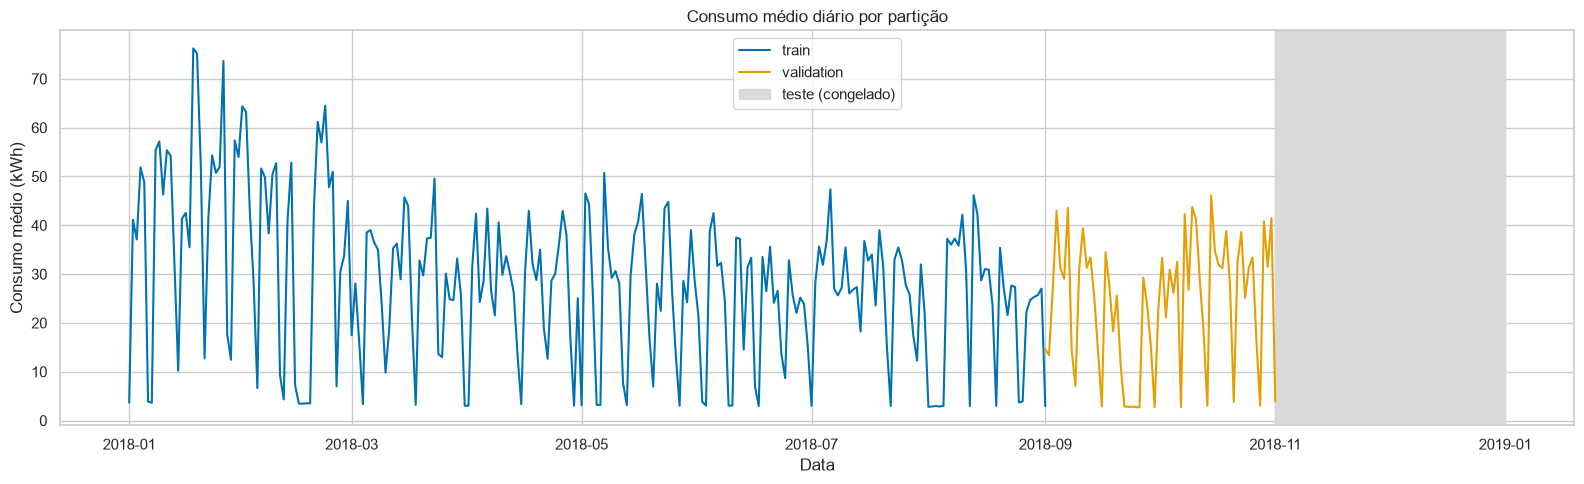

In [7]:
visible = prepared[prepared[pp.SPLIT_COLUMN] != "test"]
daily = (
    visible.set_index(pp.TIMESTAMP_COLUMN).groupby(pp.SPLIT_COLUMN)[pp.USAGE].resample("D").mean()
)

fig, ax = plt.subplots(figsize=(16, 5))
for split_name, series in daily.groupby(level=0):
    series = series.droplevel(0)
    ax.plot(series.index, series.values, color=SPLIT_COLORS[split_name], label=split_name)
test_start, test_end = split_summary.loc["test", ["inicio", "fim"]]
ax.axvspan(test_start, test_end, color="0.85", label="teste (congelado)")
ax.set(title="Consumo médio diário por partição", xlabel="Data", ylabel="Consumo médio (kWh)")
ax.legend()
fig.tight_layout()
save_figure(fig, "21_particao_temporal.png")
plt.show()

O nível de consumo muda ao longo do ano: janeiro é o mês mais alto e setembro está
entre os mais baixos. A validação, portanto, mede também robustez a **deriva** — o
que é desejável, já que o modelo final será aplicado a períodos futuros.

In [8]:
drift_columns = pp.ENERGY_COLUMNS + pp.POWER_FACTOR_COLUMNS
drift = pd.DataFrame(
    {
        "mediana_treino": train[drift_columns].median(),
        "mediana_validacao": validation[drift_columns].median(),
    }
)
drift["variacao_percentual"] = 100 * (drift["mediana_validacao"] / drift["mediana_treino"] - 1)
save_table(drift, "preprocessamento_deriva_treino_validacao.csv")
display(drift.round(2))

,mediana_treino,mediana_validacao,variacao_percentual
usage_kwh,4.75,3.64,-23.37
lagging_current_reactive_power_kvarh,4.90,5.87,19.80
leading_current_reactive_power_kvarh,0.00,0.00,NaN
lagging_current_power_factor,88.94,84.44,-5.06
leading_current_power_factor,100.00,100.00,0.00


## 5. O que `Load_Type` realmente representa

Diagnóstico feito **apenas no treino**, sem ajustar nenhum modelo. A pergunta é se as
categorias de carga descrevem comportamento elétrico ou um calendário.

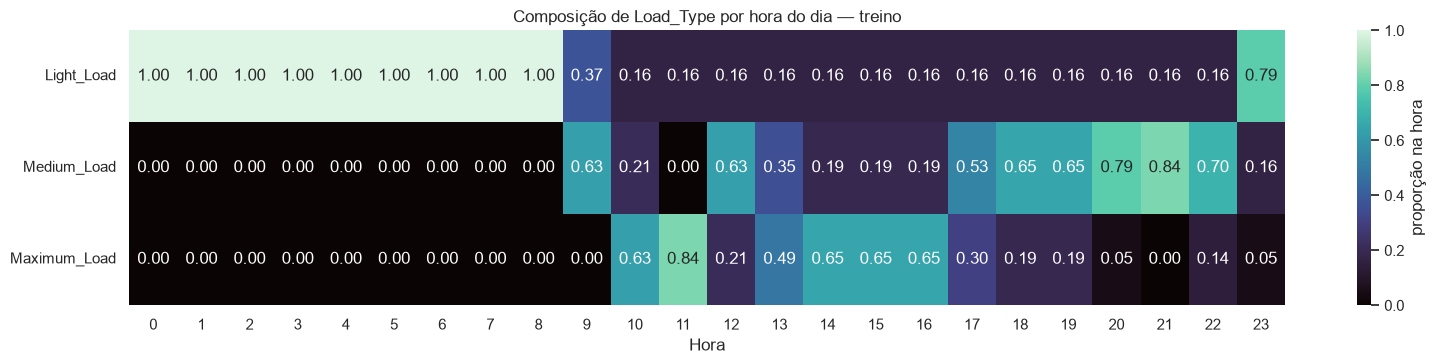

In [9]:
train_hour = train[pp.NSM] // 3_600
hour_profile = pd.crosstab(train_hour, train[LABEL_COLUMN], normalize="index")
hour_profile = hour_profile[["Light_Load", "Medium_Load", "Maximum_Load"]]

fig, ax = plt.subplots(figsize=(16, 3.8))
sns.heatmap(
    hour_profile.T,
    cmap="mako",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "proporção na hora"},
    ax=ax,
)
ax.set(title="Composição de Load_Type por hora do dia — treino", xlabel="Hora", ylabel="")
fig.tight_layout()
save_figure(fig, "22_load_type_por_hora.png")
plt.show()

In [10]:
def majority_rule_agreement(frame: pd.DataFrame, keys: list[str]) -> float:
    shares = frame.groupby(keys)[LABEL_COLUMN].agg(lambda s: s.value_counts(normalize=True).iloc[0])
    weights = frame.groupby(keys).size()
    return float((shares * weights).sum() / weights.sum())


calendar_frame = train.assign(
    hora=train_hour,
    mes=train[pp.TIMESTAMP_COLUMN].dt.month,
)
calendar_agreement = pd.DataFrame(
    [
        {
            "chaves_de_calendario": " + ".join(keys),
            "concordancia_regra_majoritaria": majority_rule_agreement(calendar_frame, keys),
        }
        for keys in (
            ["hora"],
            ["hora", pp.WEEK_STATUS],
            ["hora", pp.WEEK_STATUS, "mes"],
            [pp.NSM, pp.WEEK_STATUS, "mes"],
        )
    ]
)
save_table(calendar_agreement, "preprocessamento_load_type_vs_calendario.csv", index=False)
display(calendar_agreement.round(3))

,chaves_de_calendario,concordancia_regra_majoritaria
0,hora,0.797
1,hora + weekstatus,0.803
2,hora + weekstatus + mes,0.872
3,nsm + weekstatus + mes,0.923


**Leitura:** entre 00h e 08h59 a carga é sempre `Light_Load`, e o calendário sozinho
reproduz a grande maioria dos rótulos. `Load_Type` se comporta como uma **tabela de
horários tarifária**, não como medida do estado elétrico.

**Consequência proposta:**

- o conjunto principal de regimes (`regime`) usa **apenas variáveis elétricas**; hora e
  dia ficam de fora e são usados depois, para *descrever* os clusters;
- um conjunto `regime_with_calendar` é mantido como análise de sensibilidade;
- na avaliação externa, concordância alta com `Load_Type` obtida com calendário no
  input **não** deve ser lida como descoberta de regimes operacionais;
- para anomalias (`anomaly`) o horário **entra**, porque o contexto é o que torna uma
  leitura incomum (alto consumo às 3h é diferente de alto consumo às 11h).

## 6. Redundância entre variáveis elétricas

Correlações calculadas no treino.

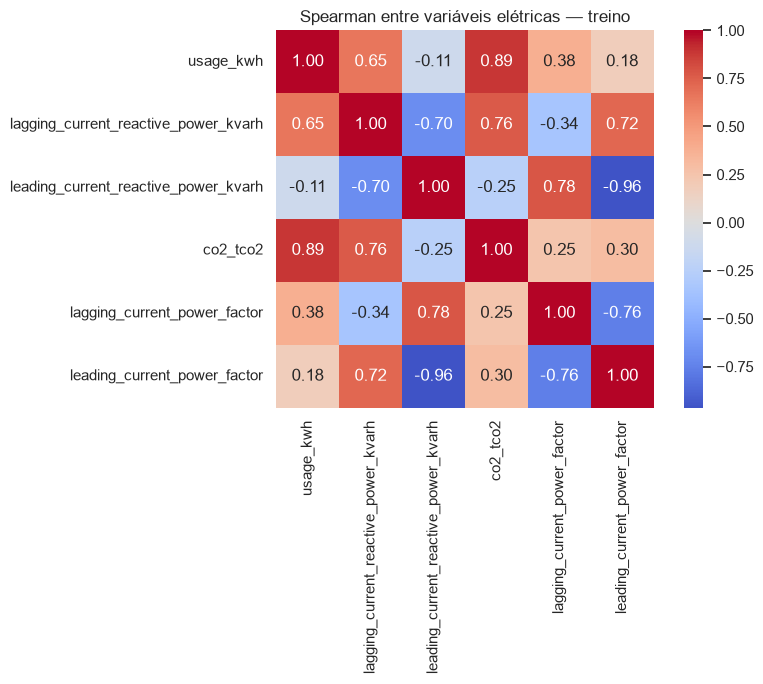

Pearson usage × CO2: 0.986
Valores distintos de CO2 no treino: 8 -> [0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07]
Proporção de CO2 = 0: 58.3%
Spearman leading kVarh × leading PF: -0.965


In [11]:
spearman_train = train[pp.ELECTRICAL_COLUMNS].corr(method="spearman")
pearson_train = train[pp.ELECTRICAL_COLUMNS].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(spearman_train, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Spearman entre variáveis elétricas — treino")
fig.tight_layout()
save_figure(fig, "23_redundancia_eletrica.png")
plt.show()

co2_values = np.sort(train[pp.CO2].unique())
print(f"Pearson usage × CO2: {pearson_train.loc[pp.USAGE, pp.CO2]:.3f}")
print(f"Valores distintos de CO2 no treino: {len(co2_values)} -> {co2_values.tolist()}")
print(f"Proporção de CO2 = 0: {(train[pp.CO2] == 0).mean():.1%}")
print(
    f"Spearman leading kVarh × leading PF: {spearman_train.loc[pp.LEADING_KVARH, pp.LEADING_PF]:.3f}"
)

**Decisão proposta:** `CO2(tCO2)` sai de todos os conjuntos de features. Ele é uma cópia
quase linear do consumo, arredondada para poucos valores discretos, e duplicaria o peso
do consumo nas distâncias. Continua disponível para perfilar os resultados.

O par *leading kVarh* × *leading PF* também é fortemente associado, mas os dois carregam
informações de escala diferentes (quantidade de energia vs. razão). Ficam ambos por ora;
remover um deles é um teste de sensibilidade para o notebook 03.

## 7. Transformações

- energia (`usage`, `lagging kVarh`, `leading kVarh`): `log1p`, para comprimir a cauda
  direita;
- fator de potência: `log1p(100 − PF)`, a distância até o fator unitário — converte a
  cauda esquerda em cauda direita e continua interpretável;
- depois, `StandardScaler` em tudo, ajustado apenas no treino;
- calendário: seno/cosseno da hora (`NSM`) e do dia da semana, mais indicador de fim de
  semana. A codificação cíclica evita que 23h45 e 00h00 fiquem "distantes".

Extremos **não** são removidos nem truncados: o objetivo do projeto inclui encontrar
observações incomuns, e cortar a cauda apagaria exatamente esse sinal.

In [12]:
transforms = {column: pp.log1p_energy for column in pp.ENERGY_COLUMNS}
transforms |= {column: pp.log1p_power_factor_deficit for column in pp.POWER_FACTOR_COLUMNS}

skew_rows = []
for column, function in transforms.items():
    original = train[column]
    transformed = pd.Series(function(original.to_numpy()))
    skew_rows.append(
        {
            "variavel": column,
            "transformacao": function.__name__,
            "assimetria_original": original.skew(),
            "assimetria_transformada": transformed.skew(),
            "proporcao_no_limite": float(((original == 0) | (original == 100)).mean()),
        }
    )
skew_table = pd.DataFrame(skew_rows).set_index("variavel")
save_table(skew_table, "preprocessamento_assimetria.csv")
display(skew_table.round(3))

,transformacao,assimetria_original,assimetria_transformada,proporcao_no_limite
variavel,,,,
usage_kwh,log1p_energy,1.142,0.429,0.000
lagging_current_reactive_power_kvarh,log1p_energy,1.447,-0.019,0.202
leading_current_reactive_power_kvarh,log1p_energy,1.745,1.261,0.689
lagging_current_power_factor,log1p_power_factor_deficit,-0.557,-0.441,0.212
leading_current_power_factor,log1p_power_factor_deficit,-1.555,1.380,0.714


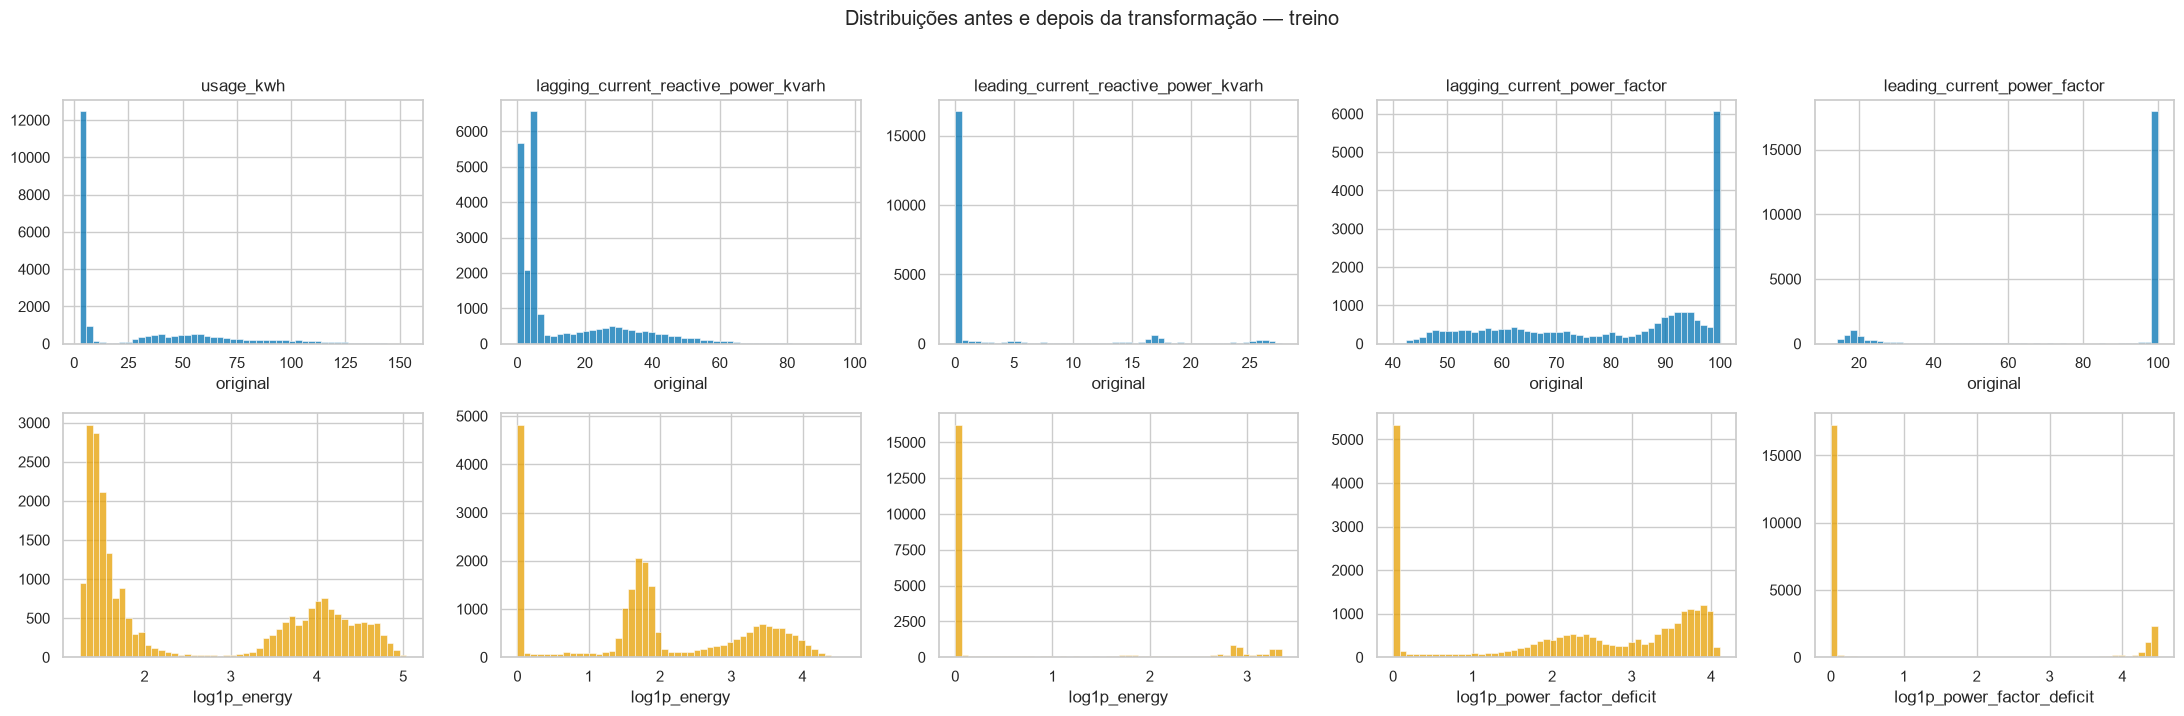

In [13]:
fig, axes = plt.subplots(2, len(transforms), figsize=(22, 7))
for i, (column, function) in enumerate(transforms.items()):
    sns.histplot(train[column], bins=50, ax=axes[0, i], color=HIGH_CONTRAST_PALETTE[0])
    sns.histplot(
        function(train[column].to_numpy()), bins=50, ax=axes[1, i], color=HIGH_CONTRAST_PALETTE[1]
    )
    axes[0, i].set(title=column, xlabel="original", ylabel="")
    axes[1, i].set(xlabel=function.__name__, ylabel="")
fig.suptitle("Distribuições antes e depois da transformação — treino", y=1.02)
fig.tight_layout()
save_figure(fig, "24_transformacoes.png")
plt.show()

**Leitura:** a transformação resolve bem o consumo e a energia reativa atrasada. As duas
variáveis *leading* continuam assimétricas porque têm uma grande massa exatamente no
limite (0 kVarh / 100% de PF) — é uma mistura de "sem corrente adiantada" com uma
distribuição contínua, e nenhuma transformação monotônica separa isso. Fica registrado
como ponto em aberto (alternativas: indicador binário de "no limite", ou modelos menos
sensíveis à forma, como Isolation Forest).

## 8. Ajuste no treino e verificação na validação

Cada conjunto de features recebe seu próprio `ColumnTransformer`, ajustado no treino.
Na validação, médias diferentes de zero e desvios diferentes de um medem a deriva já no
espaço que os modelos vão enxergar.

In [14]:
feature_set_rows = []
fitted_preprocessors = {}
for name in pp.FEATURE_SETS:
    columns = pp.feature_columns(name)
    preprocessor = pp.build_feature_preprocessor(name).fit(train[columns])
    fitted_preprocessors[name] = preprocessor
    transformed_validation = pd.DataFrame(
        preprocessor.transform(validation[columns]),
        columns=preprocessor.get_feature_names_out(),
    )
    for feature in transformed_validation:
        feature_set_rows.append(
            {
                "conjunto": name,
                "feature": feature,
                "media_validacao": transformed_validation[feature].mean(),
                "desvio_validacao": transformed_validation[feature].std(),
            }
        )

validation_space = pd.DataFrame(feature_set_rows)
save_table(validation_space, "preprocessamento_validacao_espaco_transformado.csv", index=False)
display(validation_space[validation_space["conjunto"] == "anomaly"].round(3))

for name, preprocessor in fitted_preprocessors.items():
    print(
        f"{name:>22}: {len(preprocessor.get_feature_names_out())} features -> {list(preprocessor.get_feature_names_out())}"
    )

,conjunto,feature,media_validacao,desvio_validacao
15,anomaly,usage_kwh,-0.148,0.989
16,anomaly,lagging_current_reactive_power_kvarh,0.087,0.991
17,anomaly,leading_current_reactive_power_kvarh,-0.094,0.906
18,anomaly,lagging_current_power_factor,0.221,1.040
19,anomaly,leading_current_power_factor,-0.018,1.000
20,anomaly,hour_sin,0.000,1.000
21,anomaly,hour_cos,0.000,1.000
22,anomaly,is_weekend,0.034,1.016


                regime: 5 features -> ['usage_kwh', 'lagging_current_reactive_power_kvarh', 'leading_current_reactive_power_kvarh', 'lagging_current_power_factor', 'leading_current_power_factor']
  regime_with_calendar: 10 features -> ['usage_kwh', 'lagging_current_reactive_power_kvarh', 'leading_current_reactive_power_kvarh', 'lagging_current_power_factor', 'leading_current_power_factor', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend']
               anomaly: 8 features -> ['usage_kwh', 'lagging_current_reactive_power_kvarh', 'leading_current_reactive_power_kvarh', 'lagging_current_power_factor', 'leading_current_power_factor', 'hour_sin', 'hour_cos', 'is_weekend']


## 9. Publicação dos artefatos

- `data/processed/prepared_dataset.csv`: base com timestamp corrigido, features de
  calendário e coluna `split`. `load_type` permanece **apenas** para avaliação externa.
- `metadata/preprocessing.json`: hash da base, fronteiras, conjuntos de features,
  relatório de qualidade e versões.

Os transformadores ajustados **não** são serializados aqui: `build_feature_preprocessor` é
determinístico, e o notebook 03 deve reajustá-los no treino e salvá-los junto com o
modelo final, como prevê o contrato `ModelBundle`.

In [15]:
output_columns = [
    pp.TIMESTAMP_COLUMN,
    pp.DATE_COLUMN,
    pp.SPLIT_COLUMN,
    *pp.ELECTRICAL_COLUMNS,
    pp.NSM,
    pp.WEEK_STATUS,
    pp.DAY_OF_WEEK,
    *pp.CALENDAR_FEATURES,
    LABEL_COLUMN,
]
prepared_path = PROCESSED_DIR / "prepared_dataset.csv"
prepared[output_columns].to_csv(prepared_path, index=False, encoding="utf-8")

metadata = {
    "fonte": {"arquivo": DEFAULT_DATASET.relative_to(ROOT).as_posix(), "sha256": raw_sha256},
    "qualidade": quality_report,
    "correcao_timestamp": "Leituras 00:00 (NSM=0) movidas para a meia-noite seguinte; timestamp = fim do intervalo.",
    "particoes": {
        "fronteiras_exclusivas_superiores": [b.isoformat() for b in pp.DEFAULT_SPLIT_BOUNDARIES],
        "linhas": split_summary["linhas"].astype(int).to_dict(),
        "teste_congelado": True,
    },
    "conjuntos_de_features": {name: pp.feature_columns(name) for name in pp.FEATURE_SETS},
    "transformacoes": {
        "energia": "log1p + StandardScaler",
        "fator_de_potencia": "log1p(100 - PF) + StandardScaler",
        "calendario": "seno/cosseno + StandardScaler",
        "ajuste": "somente no treino",
    },
    "excluidas": {
        pp.CO2: "cópia quase linear do consumo",
        LABEL_COLUMN: "reservada para avaliação externa",
    },
    "random_state": RANDOM_STATE,
    "versoes": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit-learn": sklearn.__version__,
    },
}
(METADATA_DIR / "preprocessing.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)
print(f"Salvo: {prepared_path.relative_to(ROOT)} ({len(prepared):,} linhas)")
print(f"Salvo: {(METADATA_DIR / 'preprocessing.json').relative_to(ROOT)}")

Salvo: artifacts\data\processed\prepared_dataset.csv (35,040 linhas)
Salvo: artifacts\metadata\preprocessing.json


## 10. Decisões e pendências

| Tema | Situação | Proposta |
| --- | --- | --- |
| Registro de meia-noite | corrigido | mover para a meia-noite seguinte |
| Partição | proposta | jan–ago / set–out / nov–dez, cronológica |
| Calendário nos regimes | proposta | fora do conjunto principal; usado para perfilar |
| CO2 | proposta | excluído das features, mantido para perfil |
| Assimetria de energia | proposta | `log1p` |
| Fator de potência | proposta | `log1p(100 − PF)` |
| Massa no limite (leading) | **em aberto** | testar indicador binário no notebook 03 |
| Par leading kVarh × PF | **em aberto** | sensibilidade com um dos dois removido |
| Limiar de anomalia | **em aberto** | calibrar na validação, não fixar 2% a priori |
| Extremos | decidido | mantidos, sem truncamento |

**Próximo passo:** notebook 03 — comparar K-Means e GMM nos conjuntos `regime` e
`regime_with_calendar`, medir estabilidade na validação e só então consultar `Load_Type`.